# Image differencing nos FITS reais SPHEREx

Oito exposições DR1 de 31/10/2025. Cada imagem é subtraída de uma referência
construída com as outras sete, usando pesos de variância. A exposição testada
não entra na própria referência. O registro usa WCS e pixels nativos próximos,
rejeitando amostras duplicadas. São subtraídos ZODI e uma mediana por exposição.

Este é um modelo inicial com cena estática e PSF gaussiana comum. Não é uma
implementação de ZOGY, Alard-Lupton ou Bramich. Ainda não há ajuste de kernel de
PSF ou calibração das diferenças espectrais LVF. Nenhum asteroide foi confirmado.

Máscara corrigida: SOURCE (bit 21) é preservado. Os demais flags de qualidade são rejeitados. Esta execução substitui os números anteriores obtidos com a máscara excessiva.

Inverse-variance leave-one-out references + shared-reference covariance scoring
Exposições: 8
Janela [h]: 1.7101238880422898


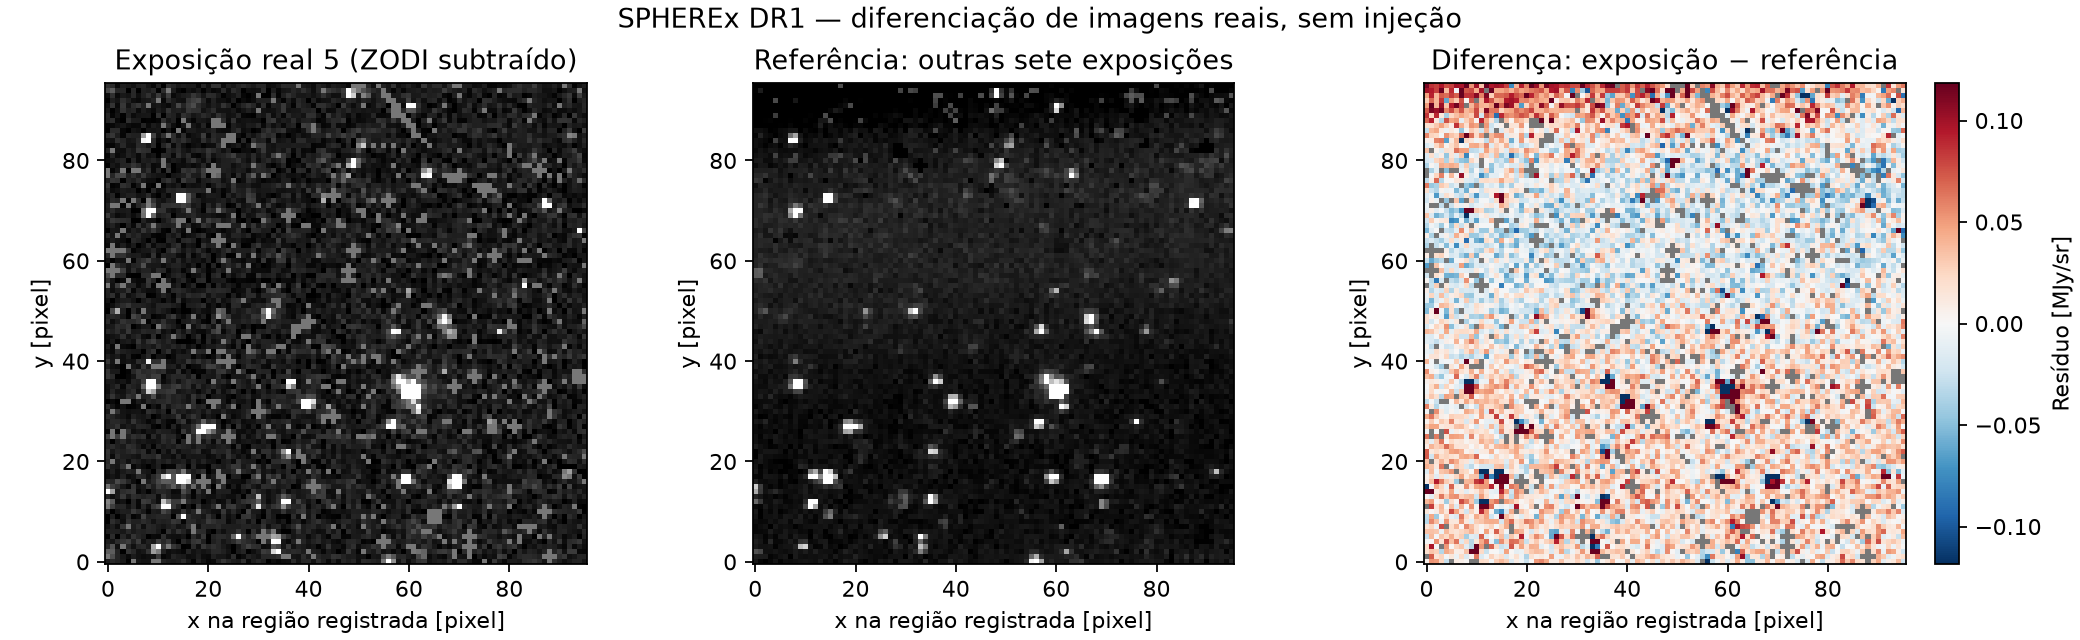

In [1]:
import json
from pathlib import Path

from astropy.table import Table
from IPython.display import JSON, Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "outputs/differencing"
report = json.loads((OUT / "report.json").read_text())
print(report["method"])
print("Exposições:", report["n_exposures"])
print("Janela [h]:", report["time_span_hours"])
display(Image(filename=str(OUT / "comparison.png")))

## Como ler a figura

À esquerda está a quinta exposição com ZODI e mediana subtraídos; no meio,
a média ponderada das outras sete exposições; à direita, a diferença.
Vermelho indica resíduo positivo e azul negativo. Cinza representa pixels sem
cobertura válida. Branco no mapa de diferença representa valores próximos de zero. Um objeto móvel pode produzir um resíduo positivo na posição
atual e negativos nas posições incluídas na referência.

Esta figura usa apenas dados reais, sem injeção. Resíduos de estrelas, cores,
PSF, fundo e registro também aparecem. Não são evidência suficiente de movimento.

In [2]:
display(Table(rows=report["residual_diagnostics"]))

exposure,obs_id,valid_fraction,normalized_residual_robust_rms,n_pixels_abs_nominal_residual_above_5
int64,str17,float64,float64,int64
0,2025W44_2B_0200_1,0.9567057291666666,1.2341775921148996,63
1,2025W44_2B_0200_2,0.9622395833333334,1.281688775835624,75
2,2025W44_2B_0200_3,0.9517144097222222,1.243153834120668,58
3,2025W44_2B_0200_4,0.9631076388888888,1.2659406642460835,67
4,2025W44_2B_0218_1,0.9289279513888888,1.2634656630459389,120
5,2025W44_2B_0218_2,0.9392361111111112,2.068978288513111,336
6,2025W44_2B_0218_3,0.9283854166666666,3.6070354447984805,2783
7,2025W44_2B_0218_4,0.9480251736111112,9.007574890020079,5893


A dispersão robusta dos resíduos divididos pela incerteza prevista deveria ficar
perto de 1 se o modelo e as variâncias descrevessem os dados. Valores elevados
indicam resíduos adicionais ou ruído não descrito. A contagem de pixels acima
de 5 é uma medida de resíduos, **não** um número de asteroides detectados.

In [3]:
rows = []
for label, control in report["controls"].items():
    rows.append(
        {
            "SNR_individual_nominal": label,
            "escore_forcado_antes": control["forced_score_before"]["score"],
            "escore_forcado_depois": control["forced_score_after"]["score"],
            "fracao_informacao_retida": control["forced_score_after"][
                "retained_information_fraction"
            ],
            "recuperacao_cega": control["assessment"]["recovered_among_proposals"],
        }
    )
display(Table(rows=rows))

SNR_individual_nominal,escore_forcado_antes,escore_forcado_depois,fracao_informacao_retida,recuperacao_cega
str3,float64,float64,float64,bool
3.0,-1.3907725512317253,4.501519128562431,0.525141878343576,False
5.0,-1.3907725512317253,8.429713581758532,0.525141878343576,False


## Controle e interpretação

As duas injeções são fontes artificiais com movimento linear sobre o fundo real
registrado. A referência é refeita depois da injeção em todas as épocas. A busca
não recebe a trajetória verdadeira. As posições são escolhidas pela cobertura
da máscara e pelas variâncias: são casos favoráveis, não uma amostra para medir
completude.

**Medição forçada** significa avaliar o escore na trajetória conhecida. Isso é
um diagnóstico de preservação de sinal; não equivale à recuperação cega.
A coluna de recuperação exige que uma das propostas da busca acompanhe a
trajetória injetada com erro máximo inferior a dois pixels.

As diferenças compartilham referências e não são independentes. O escore final
inclui essa covariância e a perda de informação por subtrair parte da própria
fonte. Fontes estacionárias são degeneradas com o céu fixo. O método ainda depende
de hipóteses de PSF e ruído que não descrevem completamente estes FITS.

Para repetir:
```bash
uv run spherex-tracking difference
```
Referências para métodos mais completos: [Alard & Lupton](https://arxiv.org/abs/astro-ph/9712287),
[ZOGY](https://arxiv.org/abs/1601.02655).

In [4]:
display(JSON(report))

<IPython.core.display.JSON object>